### Classification of Fashion Category Using Keras

In [1]:
import keras 
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
keras.backend.backend()

'tensorflow'

In [3]:
fm = keras.datasets.fashion_mnist
(X_train , y_train ) , (X_test , y_test) = fm.load_data()

In [4]:
X_train.shape

(60000, 28, 28)

In [5]:
y_train[0]

np.uint8(9)

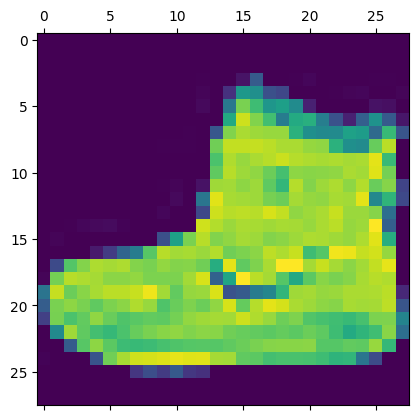

In [6]:
plt.matshow(X_train[0])

In [7]:
X_train = X_train / 255 
X_test = X_test / 255

In [8]:
from keras import Input
from keras.models import Sequential
from keras.layers import Flatten, Dense


model = Sequential()
model.add(Input(shape=(28, 28)))
model.add(Flatten())
model.add(Dense(100, activation='relu'))
model.add(Dense(10,activation='softmax'))

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(loss="sparse_categorical_crossentropy", 
                optimizer="adam",
                metrics=["accuracy"])

In [11]:
model.fit(X_train, y_train)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8238 - loss: 0.5014


In [12]:
model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8376 - loss: 0.4544


[0.45442089438438416, 0.8375999927520752]

In [13]:
yp = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [14]:
np.argmax(yp[0])

np.int64(9)

In [15]:
class_labels = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]

In [16]:
class_labels[np.argmax(yp[0])]

'Ankle boot'

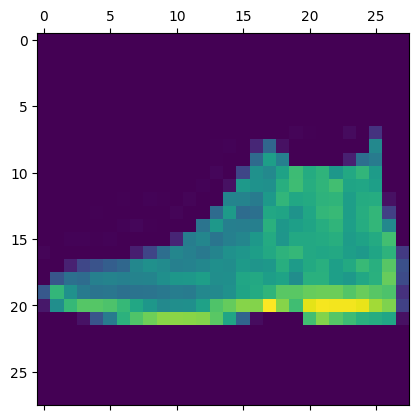

In [17]:
plt.matshow(X_test[0])